# Objectifs d'apprentissage

À l'issue de cette semaine, l'étudiant sera capable de :

- **Manipuler** les nombres complexes : forme cartésienne, polaire, module, argument, conjugué, opérations élémentaires.

- **Appliquer** la formule d'Euler pour passer d'une exponentielle complexe à une sinusoïde et vice-versa, et **interpréter géométriquement** cette transformation (rotation sur le cercle unité).

- **Distinguer** les trois notions de fréquence :
  - la **fréquence** $f$ (Hz), grandeur physique ;
  - la **pulsation analogique** $\omega = 2\pi f$ (rad/s) ;
  - la **pulsation numérique** $\Omega = \omega T_e$ (rad/échantillon), qui est un **angle**.

- **Générer** des signaux sinusoïdaux en Python avec les paramètres $A$, $\omega$, $\phi$, en temps continu échantillonné et en temps discret.

- **Visualiser** un signal temporel et sa représentation complexe (parties réelle et imaginaire), et **interpréter** le déphasage 90° entre les deux.

- **Comprendre** pourquoi l'exponentielle complexe est **la brique de base** de toute l'analyse spectrale (transformée de Fourier).

> 📦 **Dépendances** — Ce notebook nécessite : `numpy`, `matplotlib`, `pillow` (optionnel, pour générer l'animation GIF).
> ```bash
> pip install numpy matplotlib pillow
> ```

# 1. Rappels sur les nombres complexes

Un nombre complexe $z$ s'écrit sous forme **cartésienne** :

$$ z = a + j b $$

où $a$ est la **partie réelle**, $b$ la **partie imaginaire**, et $j$ l'unité imaginaire ($j^2 = -1$).

> 🔎 **Pourquoi les nombres complexes en TNS ?** — Ils permettent de représenter **simultanément** deux informations essentielles d'une sinusoïde (l'**amplitude** et la **phase**) sous la forme d'**un seul nombre**. C'est ce qui rend les calculs de filtrage, modulation et transformée de Fourier **extrêmement compacts**. Sans eux, on traînerait partout des couples (magnitude, phase) sans lien mathématique naturel.

> 🔎 **Interprétation géométrique** — Le plan complexe $\mathbb{C}$ est un **espace de rotation**. Multiplier deux nombres complexes **additionne leurs angles** et **multiplie leurs modules** : c'est ce qui fait de $\mathbb{C}$ l'outil naturel pour décrire des oscillations et des phases.

---

## 1.1 Module et argument

- **Module** : $|z| = \sqrt{a^2 + b^2}$ — c'est la **distance à l'origine** dans le plan complexe.
- **Argument** : $\arg(z) = \theta = \operatorname{atan2}(b, a)$ — c'est l'**angle polaire**, en radians, mesuré dans le sens trigonométrique.

**Forme polaire** :
$$ z = |z| \, e^{j\theta} $$

> ⚠️ **Piège du `atan` simple** — Utilisez toujours `atan2(b, a)` en pratique et **jamais** `arctan(b/a)` : `atan2` tient compte des signes de $a$ et $b$ et retourne un angle dans $[-\pi, \pi]$, tandis que `arctan` retourne toujours un angle dans $]-\pi/2, \pi/2[$ et **confond** par exemple $1 + j$ et $-1 - j$.

---

## 1.2 Conjugué

$$ z^* = a - j b = |z| \, e^{-j\theta} $$

Le conjugué est une **réflexion par rapport à l'axe réel**. On l'utilise pour :
- Calculer le module : $|z|^2 = z \cdot z^*$.
- Calculer une division : $\dfrac{z_1}{z_2} = \dfrac{z_1 z_2^*}{|z_2|^2}$.
- Extraire la partie réelle : $\Re\{z\} = \dfrac{z + z^*}{2}$.

---

## 1.3 Opérations

- **Addition** : $(a+jb) + (c+jd) = (a+c) + j(b+d)$ — s'effectue terme à terme (comme une addition de vecteurs).
- **Multiplication** : $(a+jb)(c+jd) = (ac - bd) + j(ad + bc)$ — **multiplie les modules, additionne les angles**.
- **Division** : utiliser le conjugué — **divise les modules, soustrait les angles**.

> 🔑 **Phrase à retenir** — En forme polaire, la multiplication complexe **transforme un produit en addition d'angles**. C'est cette propriété qui fait que la réponse en fréquence d'un filtre LTI se **multiplie** au signal d'entrée en notation complexe, alors qu'en notation réelle elle **convole**.

---

## 1.4 Formule d'Euler

$$ e^{j\theta} = \cos \theta + j \sin \theta $$

> 🔎 **Interprétation géométrique** — $e^{j\theta}$ est le point du **cercle unité** situé à l'angle $\theta$. La formule d'Euler dit simplement : « **tourner de $\theta$ dans le plan complexe revient à se déplacer horizontalement de $\cos\theta$ et verticalement de $\sin\theta$** ».

> 🔎 **D'où vient-elle ?** — En développant $e^{j\theta}$, $\cos\theta$ et $\sin\theta$ en série de Taylor, on obtient respectivement $\sum \frac{(j\theta)^n}{n!}$, $\sum \frac{(-1)^n \theta^{2n}}{(2n)!}$ et $\sum \frac{(-1)^n \theta^{2n+1}}{(2n+1)!}$. En séparant les termes pairs et impairs de la première série (en utilisant $j^{2n} = (-1)^n$ et $j^{2n+1} = j (-1)^n$), on retrouve exactement les deux autres. La formule d'Euler est donc une **identité analytique profonde**, pas un postulat.

**Conséquences fondamentales :**
- $\cos \theta = \dfrac{e^{j\theta} + e^{-j\theta}}{2}$ — le cosinus est la **partie paire** de l'exponentielle.
- $\sin \theta = \dfrac{e^{j\theta} - e^{-j\theta}}{2j}$ — le sinus est la **partie impaire**.

> 🔑 **Ces deux formules sont le pont** entre le monde des exponentielles (que les systèmes LTI adorent, car ce sont leurs fonctions propres) et le monde des signaux réels (que l'on mesure physiquement). **Toute l'analyse de Fourier repose sur ce passage.**

---

## 1.5 Sinusoïdes

Un signal sinusoïdal s'écrit :

$$ x(t) = A \cos(\omega t + \phi) \quad \text{(temps continu)} $$

$$ x[n] = A \cos(\Omega n + \phi) \quad \text{(temps discret)} $$

où :
- $A$ : **amplitude** (positive ou nulle) ;
- $\phi$ : **phase à l'origine** (radians) ;
- $\omega$ : **pulsation analogique** (rad/s), liée à $f$ (Hz) par $\omega = 2\pi f$ ;
- $\Omega$ : **pulsation numérique** (rad/échantillon), liée à $\omega$ et à la période d'échantillonnage $T_e$ par $\Omega = \omega T_e$.

**Lien avec l'exponentielle complexe :**

$$ A \cos(\omega t + \phi) = \Re\{ A e^{j(\omega t + \phi)} \} $$

De même :

$$ A \sin(\omega t + \phi) = \Im\{ A e^{j(\omega t + \phi)} \} $$

> 🔎 **Pourquoi ce détour par $\mathbb{C}$ ?** — Parce que les systèmes LTI **transforment** $e^{j\omega t}$ en $H(j\omega) \cdot e^{j\omega t}$ : l'exponentielle complexe est **fonction propre**. On peut donc calculer la réponse à **n'importe quelle** sinusoïde (via la décomposition en Fourier) en ne connaissant que $H(j\omega)$. C'est l'**idée maîtresse de tout le cours**.

---

## 1.6 Attention aux trois notions de fréquence

| Grandeur | Symbole | Unité | Domaine | Lien |
| :--- | :---: | :---: | :---: | :--- |
| Fréquence physique | $f$ | Hz | $[0, +\infty[$ | — |
| Pulsation analogique | $\omega$ | rad/s | $[0, +\infty[$ | $\omega = 2\pi f$ |
| Pulsation numérique | $\Omega$ | rad/échantillon | $]-\pi, \pi]$ | $\Omega = \omega T_e$ |

> ⚠️ **Erreur fréquente** — Ne pas confondre $\omega$ et $\Omega$ :
> - $\omega$ a la dimension d'une **vitesse angulaire** (rad/s), elle vit sur $[0, +\infty[$ ;
> - $\Omega$ est un **angle par échantillon**, il vit sur $]-\pi, \pi]$ (à cause de la périodicité spectrale, cf. semaine 1).
> Confondre les deux, c'est multiplier par $T_e$ sans le savoir et **casser la cohérence dimensionnelle** des formules.


# 2. Préparation Python

Nous allons utiliser les bibliothèques suivantes :
- `numpy` pour les calculs numériques et les fonctions mathématiques (complexes, trigonométriques, FFT).
- `matplotlib.pyplot` pour les tracés (temporels, fréquentiels, complexes).

> 💡 **Convention Python** — En Python, l'unité imaginaire s'écrit **`1j`** (pas `i` ni `j` seuls). Ainsi $3 + 4j$ s'écrit `3 + 4j` et $e^{j\pi/4}$ s'écrit `np.exp(1j * np.pi / 4)`.

Exécutez la cellule suivante pour les importer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle
import warnings

# On cible uniquement les avertissements numériques connus (division par 0, etc.)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Reproductibilité (bonne pratique, même sans tirage aléatoire ici)
np.random.seed(42)

# Configuration graphique cohérente pour tout le notebook
plt.rcParams.update({
    'figure.figsize': (12, 4),
    'font.size': 11,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 1.5,
    'figure.autolayout': True,
    'savefig.bbox': 'tight',
    'figure.dpi': 100,
})

print("Bibliothèques chargées : numpy, matplotlib")
print("Version numpy      :", np.__version__)
print("Version matplotlib :", plt.matplotlib.__version__)

Bibliothèques chargées : numpy, matplotlib
Version numpy      : 2.5.4
Version matplotlib : 3.11.2


# 3. Génération de signaux sinusoïdaux

Nous allons créer des signaux en temps continu (échantillonnés) et en temps discret.

> 🔎 **Rappel important** — Un calculateur numérique **ne peut pas représenter un vrai signal continu**. On simule un signal « pseudo-continu » en l'échantillonnant à une fréquence **très élevée** devant la fréquence du signal (règle empirique : $f_e \geq 20 f_{\max}$ pour un rendu visuel fluide).

## 3.1 Signal sinusoïdal continu échantillonné

### Exemple : $x(t) = 2 \cos(2\pi \cdot 3 \, t + \pi/4)$

Paramètres :
- Amplitude $A = 2$
- Fréquence $f = 3$ Hz (donc $\omega = 2\pi f = 6\pi$ rad/s)
- Phase $\phi = \pi/4$ rad

On génère un vecteur de temps entre 0 et 1 seconde avec un pas de 1 ms.

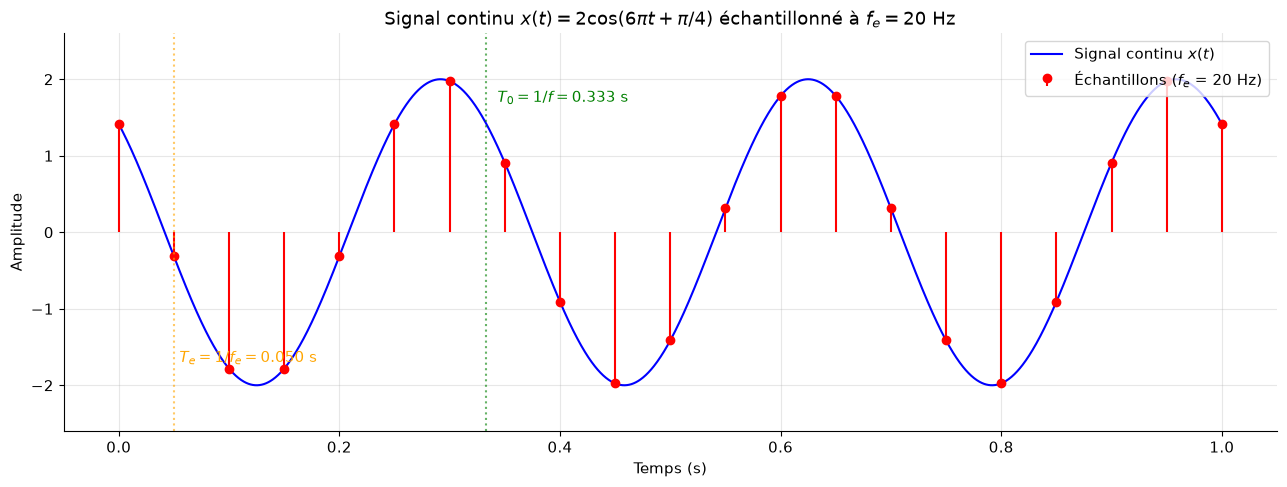

Nombre d'échantillons par période du signal : 6.67
Critère de Nyquist : fe = 20 Hz, 2f = 6.0 Hz → ✓ respecté


In [2]:
# =====================================================
# Signal sinusoïdal continu ET démonstration d'échantillonnage
# =====================================================
A, f, phi = 2.0, 3.0, np.pi/4

# --- Signal continu (simulé par sur-échantillonnage) ---
t_cont = np.linspace(0, 1, 2000)
x_cont = A * np.cos(2*np.pi*f*t_cont + phi)

# --- Échantillonnage à fe = 20 Hz ---
fe = 20
Te = 1/fe
n = np.arange(0, int(fe) + 1)
t_ech = n * Te
x_ech = A * np.cos(2*np.pi*f*t_ech + phi)

# --- Tracé ---
plt.figure(figsize=(13, 5))
plt.plot(t_cont, x_cont, 'b-', lw=1.5, label='Signal continu $x(t)$')
plt.stem(t_ech, x_ech, linefmt='r-', markerfmt='ro', basefmt=' ',
         label=rf'Échantillons ($f_e$ = {fe} Hz)')

# Annotation : période du signal
T0 = 1/f
plt.axvline(T0, color='green', ls=':', alpha=0.6)
plt.text(T0 + 0.01, A*0.85, rf'$T_0 = 1/f = {T0:.3f}$ s',
         color='green', fontsize=11)

# Annotation : période d'échantillonnage
plt.axvline(Te, color='orange', ls=':', alpha=0.6)
plt.text(Te + 0.005, -A*0.85, rf'$T_e = 1/f_e = {Te:.3f}$ s',
         color='orange', fontsize=11)

plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.title(rf'Signal continu $x(t) = 2\cos(6\pi t + \pi/4)$ échantillonné à $f_e = {fe}$ Hz')
plt.ylim(-A*1.3, A*1.3)
plt.legend(loc='upper right')
plt.show()

print(f"Nombre d'échantillons par période du signal : {T0/Te:.2f}")
print(f"Critère de Nyquist : fe = {fe} Hz, 2f = {2*f} Hz → {'✓ respecté' if fe > 2*f else '✗ violé'}")

## 3.2 Signal sinusoïdal discret

En traitement numérique, on manipule des **suites** $x[n]$. Un signal discret peut être obtenu par échantillonnage d'un signal continu avec une période $T_e = 1/f_e$. On a alors :

$$ x[n] = x(n T_e) = A \cos(\omega n T_e + \phi) = A \cos(\Omega n + \phi) $$

avec la **pulsation numérique** :

$$ \Omega = \omega T_e = 2\pi \frac{f}{f_e} \quad \text{(en rad/échantillon)} $$

> 🔎 **Interprétation physique de $\Omega$** — $\Omega$ est **l'angle dont tourne le phaseur à chaque échantillon**. Si $\Omega = \pi/6$, le signal avance de 30° à chaque pas. C'est cette quantité qui intervient dans **toutes** les formules de TNS à temps discret (transformée en Z, réponse fréquentielle $H(e^{j\Omega})$, FFT…).

> 🔎 **Rappel du critère de Nyquist** — Pour éviter le repliement de spectre, il faut $f_e > 2 f_{\max}$, ce qui équivaut à $|\Omega| < \pi$. Autrement dit : **la pulsation numérique doit rester dans l'intervalle $]-\pi, \pi[$**. C'est là qu'on retrouve la **périodicité spectrale** vue en semaine 1.

### Exemple : $x[n] = \cos(\pi n / 6)$

Ici $\Omega = \pi/6$, $A = 1$, $\phi = 0$. On génère les échantillons pour $n = 0$ à $20$.

**Période du signal** : $N = 2\pi / \Omega = 12$ échantillons (entier → le signal est **périodique** en temps discret).

Pulsation numérique Ω = π/6 rad/échantillon
Période théorique N = 2π/Ω = 12 échantillons
Vérification : x[0] = 1.0000, x[12] = 1.0000, x[24] = 1.0000
Périodique : ✓ OUI


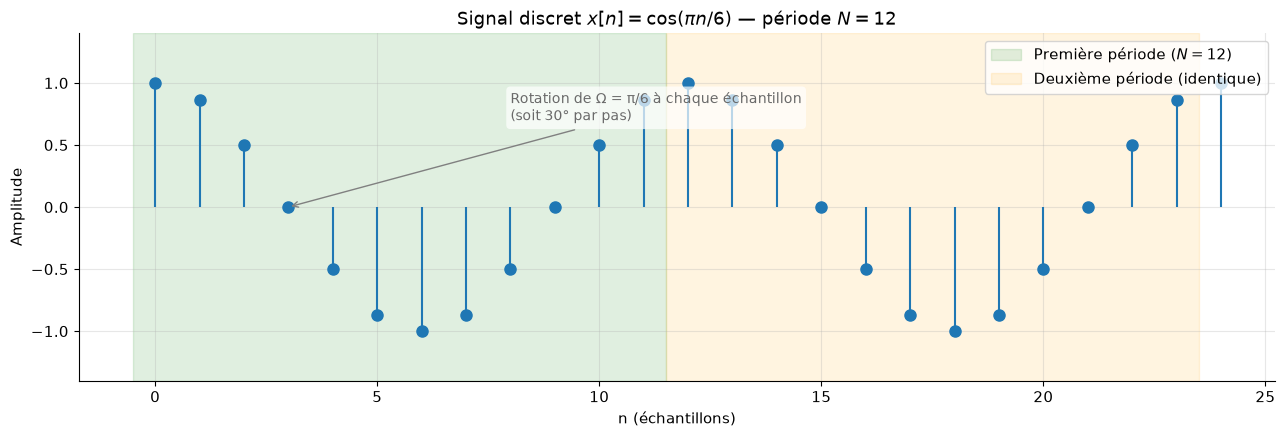

In [3]:
# =====================================================
# Signal sinusoïdal discret + mise en évidence de la période
# =====================================================
A, Omega, phi = 1.0, np.pi/6, 0.0
n = np.arange(0, 25)

x = A * np.cos(Omega * n + phi)

# Période théorique
N_period = 2*np.pi / Omega       # = 12 échantillons
print(f"Pulsation numérique Ω = π/6 rad/échantillon")
print(f"Période théorique N = 2π/Ω = {N_period:.0f} échantillons")
print(f"Vérification : x[0] = {x[0]:.4f}, x[12] = {x[12]:.4f}, x[24] = {x[24]:.4f}")
print(f"Périodique : {'✓ OUI' if np.isclose(x[0], x[12]) else '✗ NON'}")

# --- Tracé ---
plt.figure(figsize=(13, 4.5))
markerline, stemlines, baseline = plt.stem(n, x, basefmt=' ',
                                           linefmt='C0-', markerfmt='C0o')
plt.setp(markerline, markersize=8)
plt.setp(stemlines, linewidth=1.5)

# Zone de la première période
plt.axvspan(-0.5, N_period - 0.5, alpha=0.12, color='green',
            label=rf'Première période ($N = {N_period:.0f}$)')
# Zone de la deuxième période
plt.axvspan(N_period - 0.5, 2*N_period - 0.5, alpha=0.12, color='orange',
            label='Deuxième période (identique)')

# Annotation : sens de rotation du phaseur
plt.annotate('Rotation de Ω = π/6 à chaque échantillon\n(soit 30° par pas)',
             xy=(3, x[3]), xytext=(8, 0.7),
             arrowprops=dict(arrowstyle='->', color='gray'),
             fontsize=10, color='dimgray',
             bbox=dict(boxstyle='round', fc='white', ec='none', alpha=0.7))

plt.xlabel('n (échantillons)')
plt.ylabel('Amplitude')
plt.title(r'Signal discret $x[n] = \cos(\pi n / 6)$ — période $N = 12$')
plt.ylim(-1.4, 1.4)
plt.legend(loc='upper right')
plt.show()

## 3.3 Influence des paramètres

Modifions l'amplitude, la fréquence et la phase pour observer leurs effets respectifs.

### Effet de chaque paramètre (à retenir)

| Paramètre | Effet sur la forme du signal | Effet sur le spectre |
| :--- | :--- | :--- |
| **$A$ (amplitude)** | Dilatation verticale | Multiplie les raies spectrales par $|A|$ |
| **$\Omega$ (pulsation)** | Dilatation/compression horizontale | Déplace les raies à $\pm\Omega$ |
| **$\phi$ (phase)** | Translation horizontale | Ajoute un déphasage complexe $e^{j\phi}$ |

### Exemple : comparer trois signaux

Nous allons tracer :
- $x_1[n] = \cos(\pi n / 6)$ — référence
- $x_2[n] = 2 \cos(\pi n / 6)$ — amplitude doublée
- $x_3[n] = \cos(\pi n / 3)$ — pulsation doublée
- $x_4[n] = \cos(\pi n / 6 + \pi/2)$ — phase décalée de $90^\circ$

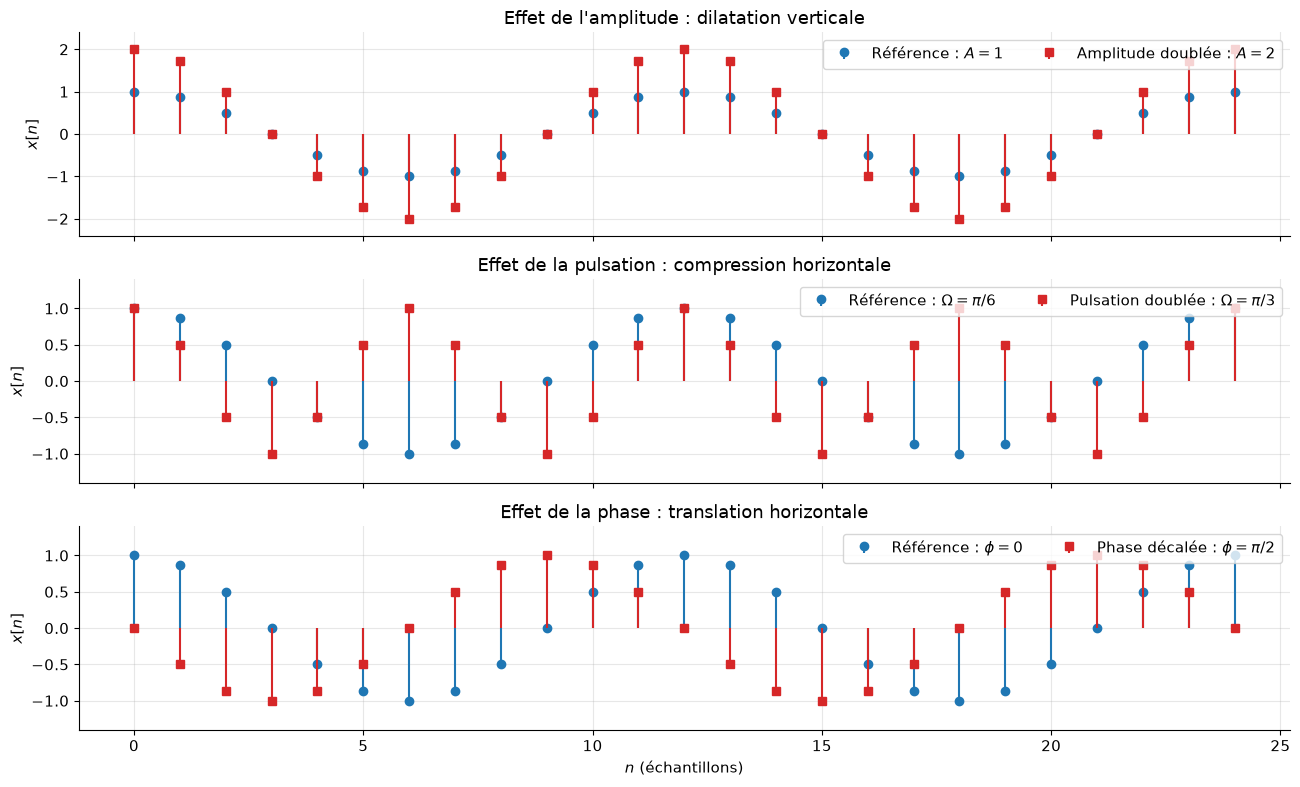

In [4]:
# =====================================================
# Influence des paramètres A, Ω, φ sur x[n] = A cos(Ω n + φ)
# =====================================================
n = np.arange(0, 25)

# --- Variations indépendantes ---
x_ref   = 1.0 * np.cos(np.pi/6 * n)              # Référence
x_A     = 2.0 * np.cos(np.pi/6 * n)              # Amplitude doublée
x_Omega = 1.0 * np.cos(np.pi/3 * n)              # Pulsation doublée
x_phi   = 1.0 * np.cos(np.pi/6 * n + np.pi/2)    # Phase décalée de 90°

# --- Tracé ---
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

# Ligne 1 : effet de A
axes[0].stem(n, x_ref, linefmt='C0-', markerfmt='C0o', basefmt=' ',
             label='Référence : $A=1$')
axes[0].stem(n, x_A,   linefmt='C3-', markerfmt='C3s', basefmt=' ',
             label='Amplitude doublée : $A=2$')
axes[0].set_ylabel('$x[n]$')
axes[0].set_title("Effet de l'amplitude : dilatation verticale")
axes[0].legend(loc='upper right', ncol=2)
axes[0].set_ylim(-2.4, 2.4)

# Ligne 2 : effet de Ω
axes[1].stem(n, x_ref,   linefmt='C0-', markerfmt='C0o', basefmt=' ',
             label=r'Référence : $\Omega = \pi/6$')
axes[1].stem(n, x_Omega, linefmt='C3-', markerfmt='C3s', basefmt=' ',
             label=r'Pulsation doublée : $\Omega = \pi/3$')
axes[1].set_ylabel('$x[n]$')
axes[1].set_title('Effet de la pulsation : compression horizontale')
axes[1].legend(loc='upper right', ncol=2)
axes[1].set_ylim(-1.4, 1.4)

# Ligne 3 : effet de φ
axes[2].stem(n, x_ref, linefmt='C0-', markerfmt='C0o', basefmt=' ',
             label=r'Référence : $\phi = 0$')
axes[2].stem(n, x_phi, linefmt='C3-', markerfmt='C3s', basefmt=' ',
             label=r'Phase décalée : $\phi = \pi/2$')
axes[2].set_xlabel('$n$ (échantillons)')
axes[2].set_ylabel('$x[n]$')
axes[2].set_title('Effet de la phase : translation horizontale')
axes[2].legend(loc='upper right', ncol=2)
axes[2].set_ylim(-1.4, 1.4)

plt.tight_layout()
plt.show()

## 3.4 Comparaison explicite $\omega$ (rad/s) vs $\Omega$ (rad/échantillon)

Illustrons concrètement la différence dimensionnelle entre $\omega$ et $\Omega$ : mêmes paramètres physiques, mais deux représentations différentes selon qu'on regarde le temps continu ou le temps discret.

COMPARAISON DES DEUX PULSATIONS
Fréquence physique       f     = 2.000 Hz
Pulsation analogique     ω     = 12.5664 rad/s
Fréquence d'échantillonnage fe = 16.0 Hz
Pulsation numérique      Ω     = ω/fe = 0.7854 rad/échantillon
                          Ω     = 45.00° par échantillon

Période numérique : N = 2π/Ω = 8.000 échantillons
Nombre d'échantillons par période du signal : fe/f = 8.0


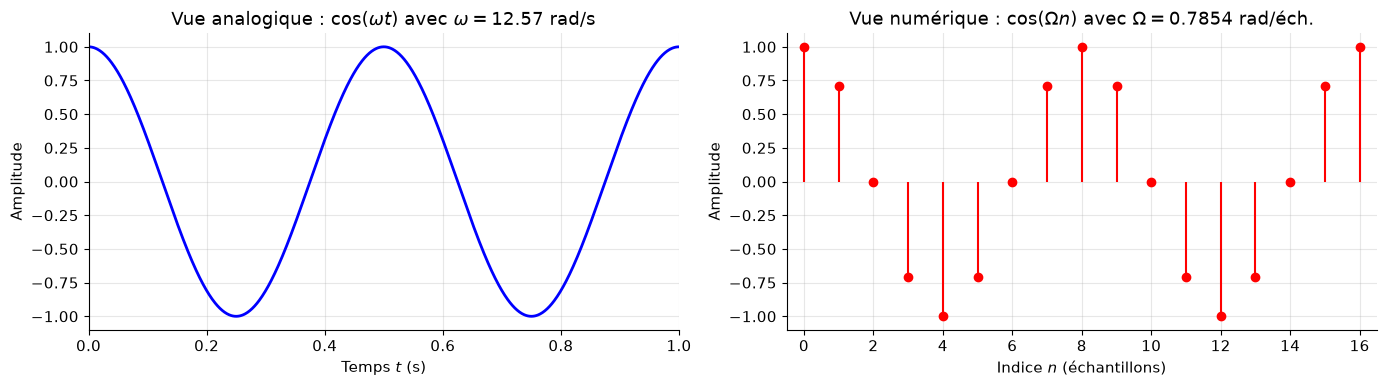


⚠️  ATTENTION : ne pas confondre ω (rad/s) et Ω (rad/échantillon).
   Ils diffèrent d'un facteur Te = 1/fe : Ω = ω · Te


In [5]:
# =====================================================
# Comparaison ω (rad/s) et Ω (rad/échantillon)
# =====================================================
f_signal = 2.0        # Hz
omega     = 2*np.pi*f_signal  # rad/s
fe        = 16.0      # Hz
Omega     = omega / fe        # rad/échantillon

print("=" * 55)
print("COMPARAISON DES DEUX PULSATIONS")
print("=" * 55)
print(f"Fréquence physique       f     = {f_signal:.3f} Hz")
print(f"Pulsation analogique     ω     = {omega:.4f} rad/s")
print(f"Fréquence d'échantillonnage fe = {fe:.1f} Hz")
print(f"Pulsation numérique      Ω     = ω/fe = {Omega:.4f} rad/échantillon")
print(f"                          Ω     = {np.degrees(Omega):.2f}° par échantillon")
print(f"\nPériode numérique : N = 2π/Ω = {2*np.pi/Omega:.3f} échantillons")
print(f"Nombre d'échantillons par période du signal : fe/f = {fe/f_signal:.1f}")

# --- Tracé comparatif ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Vue analogique : x(t) en fonction de t
t = np.linspace(0, 1, 1000)
x_t = np.cos(omega * t + 0)
axes[0].plot(t, x_t, 'b-', lw=2)
axes[0].set_xlabel('Temps $t$ (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title(rf'Vue analogique : $\cos(\omega t)$ avec $\omega = {omega:.2f}$ rad/s')
axes[0].set_xlim(0, 1)

# Vue numérique : x[n] en fonction de n
n = np.arange(0, int(fe) + 1)
x_n = np.cos(Omega * n + 0)
axes[1].stem(n, x_n, basefmt=' ', linefmt='r-', markerfmt='ro')
axes[1].set_xlabel('Indice $n$ (échantillons)')
axes[1].set_ylabel('Amplitude')
axes[1].set_title(rf'Vue numérique : $\cos(\Omega n)$ avec $\Omega = {Omega:.4f}$ rad/éch.')
axes[1].set_xlim(-0.5, fe + 0.5)

plt.tight_layout()
plt.show()

print("\n⚠️  ATTENTION : ne pas confondre ω (rad/s) et Ω (rad/échantillon).")
print("   Ils diffèrent d'un facteur Te = 1/fe : Ω = ω · Te")

## 3.5 Démonstration du repliement (aliasing)

Le critère de Nyquist dit qu'il faut $f_e > 2 f$. Voyons ce qui se passe **quand on le viole** : un signal à 3 Hz échantillonné à 4 Hz va **paraître** être un signal à 1 Hz (fréquence repliée $|f - f_e| = |3 - 4| = 1$ Hz). C'est le phénomène d'**aliasing**.

DÉMONSTRATION DU REPLIEMENT SPECTRAL
Signal réel         : f     = 3.0 Hz
Fréquence échantill. : fe    = 4.0 Hz
Critère de Nyquist  : fe > 2f = 6.0 Hz → ✗ VIOLÉ
Fréquence apparente : |f - fe| = 1.0 Hz  ← le signal semble être à 1.0 Hz !


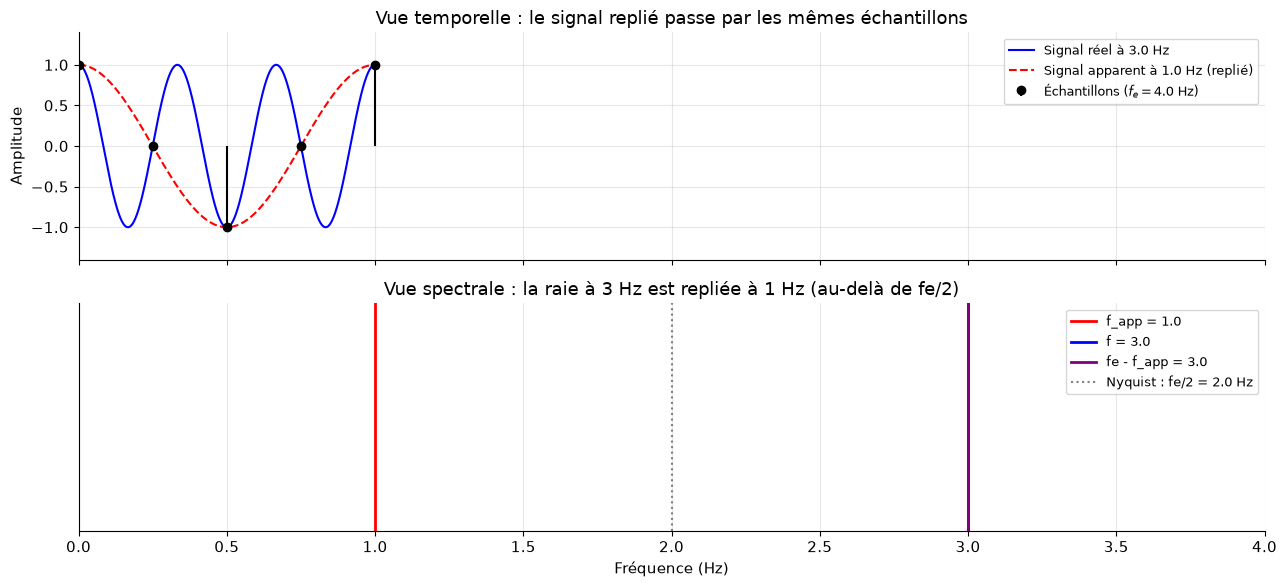


🔑 À retenir : un signal à 3 Hz échantillonné à 4 Hz est indiscernable
   d'un signal à 1 Hz. C'est pour cela que le filtre anti-aliasing est
   indispensable avant toute numérisation.


In [6]:
# =====================================================
# Démonstration du repliement de spectre (aliasing)
# =====================================================
f_vrai = 3.0     # Hz — fréquence du signal réel
fe_bas = 4.0     # Hz — fréquence d'échantillonnage INSUFFISANTE (fe < 2f)
f_app  = abs(f_vrai - fe_bas)   # fréquence apparente après repliement

print("=" * 55)
print("DÉMONSTRATION DU REPLIEMENT SPECTRAL")
print("=" * 55)
print(f"Signal réel         : f     = {f_vrai} Hz")
print(f"Fréquence échantill. : fe    = {fe_bas} Hz")
print(f"Critère de Nyquist  : fe > 2f = {2*f_vrai} Hz → {'✓ respecté' if fe_bas > 2*f_vrai else '✗ VIOLÉ'}")
print(f"Fréquence apparente : |f - fe| = {f_app} Hz  ← le signal semble être à {f_app} Hz !")

# --- Tracés ---
t_fin = np.linspace(0, 1, 2000)
x_reel = np.cos(2*np.pi*f_vrai*t_fin)
x_app  = np.cos(2*np.pi*f_app*t_fin)

n_viol = np.arange(0, int(fe_bas) + 1)
t_viol = n_viol / fe_bas
x_viol = np.cos(2*np.pi*f_vrai*t_viol)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].plot(t_fin, x_reel, 'b-', lw=1.5, label=f'Signal réel à {f_vrai} Hz')
axes[0].plot(t_fin, x_app, 'r--', lw=1.5, label=f'Signal apparent à {f_app} Hz (replié)')
axes[0].stem(t_viol, x_viol, linefmt='k-', markerfmt='ko', basefmt=' ',
             label=f'Échantillons ($f_e = {fe_bas}$ Hz)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Vue temporelle : le signal replié passe par les mêmes échantillons')
axes[0].legend(loc='upper right', fontsize=9)
axes[0].set_ylim(-1.4, 1.4)

# Spectre : raies réelles vs raies apparentes
freqs = np.array([f_app, f_vrai, fe_bas - f_app])
labels = [f'f_app = {f_app}', f'f = {f_vrai}', f'fe - f_app = {fe_bas - f_app}']
colors = ['red', 'blue', 'purple']
for fr, lb, c in zip(freqs, labels, colors):
    axes[1].axvline(fr, color=c, lw=2, label=lb)
axes[1].axvline(fe_bas/2, color='gray', ls=':', lw=1.5,
                label=f'Nyquist : fe/2 = {fe_bas/2} Hz')
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_xlim(0, fe_bas)
axes[1].set_yticks([])
axes[1].set_title('Vue spectrale : la raie à 3 Hz est repliée à 1 Hz (au-delà de fe/2)')
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

print("\n🔑 À retenir : un signal à 3 Hz échantillonné à 4 Hz est indiscernable")
print("   d'un signal à 1 Hz. C'est pour cela que le filtre anti-aliasing est")
print("   indispensable avant toute numérisation.")

# 4. Représentation complexe d'un signal sinusoïdal

Un signal réel $x(t) = A \cos(\omega t + \phi)$ peut être vu comme la **partie réelle** de l'exponentielle complexe :

$$ z(t) = A \, e^{j(\omega t + \phi)} = \underbrace{A \cos(\omega t + \phi)}_{\Re\{z\}} + j\, \underbrace{A \sin(\omega t + \phi)}_{\Im\{z\}} $$

> 🔎 **Interprétation visuelle — le phaseur** — Dans le plan complexe, $z(t)$ est un **vecteur de longueur $A$ tournant à la vitesse angulaire $\omega$**. La projection sur l'axe réel donne le cosinus, la projection sur l'axe imaginaire donne le sinus. **Le signal réel est une « ombre » du phaseur complexe sur l'axe horizontal.**

> 🔎 **Interprétation 3D — l'hélice** — Si on trace $t$ en abscisse, $\Re\{z\}$ en ordonnée et $\Im\{z\}$ en « profondeur », la courbe décrite par $z(t)$ est une **hélice** dont l'axe est le temps. C'est la visualisation la plus fidèle de l'exponentielle complexe (une sinusoïde peut être vue comme la projection de cette hélice sur un plan vertical).

> 🔑 **Pourquoi cette notion est essentielle pour la suite ?** — Les systèmes LTI transforment un phaseur en un autre phaseur de **même fréquence** mais d'amplitude et de phase modifiées par $H(j\omega)$. Toute la boîte à outils de filtrage, de modulation et de transformée de Fourier repose sur cette propriété.

Nous allons générer une exponentielle complexe et afficher ses parties réelle et imaginaire.

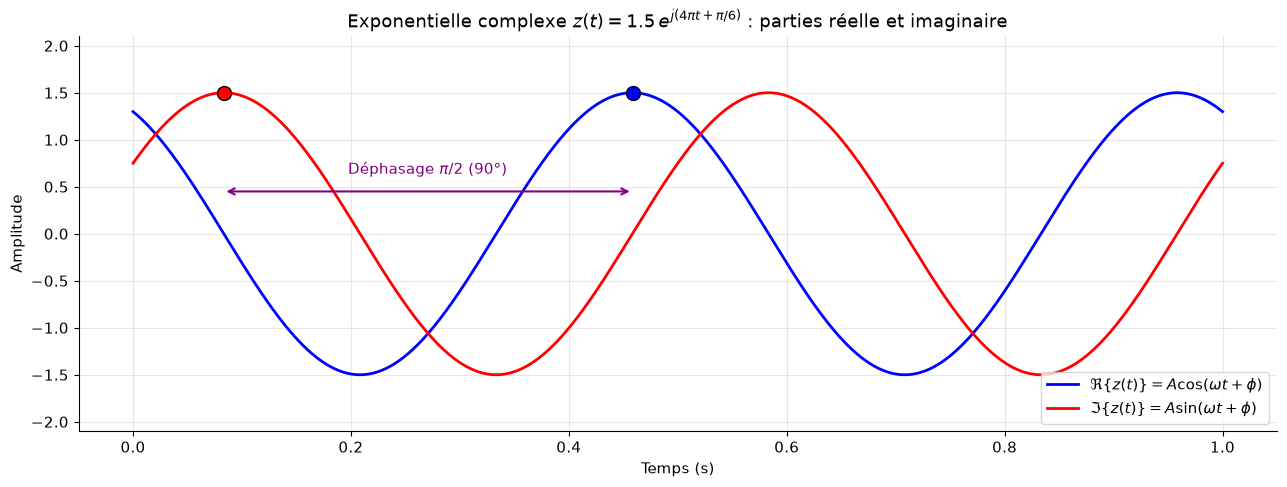

In [7]:
# =====================================================
# Exponentielle complexe : parties réelle et imaginaire
# =====================================================
A, f, phi = 1.5, 2.0, np.pi/6
t = np.linspace(0, 1, 1000)

z = A * np.exp(1j * (2*np.pi*f*t + phi))
re_z = np.real(z)
im_z = np.imag(z)

plt.figure(figsize=(13, 5))

# Courbes
plt.plot(t, re_z, 'b-', lw=2, label=r'$\Re\{z(t)\} = A\cos(\omega t + \phi)$')
plt.plot(t, im_z, 'r-', lw=2, label=r'$\Im\{z(t)\} = A\sin(\omega t + \phi)$')

# Déphasage : marqueurs sur les deux premiers maxima
idx_re_max = np.argmax(re_z)
idx_im_max = np.argmax(im_z)
plt.scatter(t[idx_re_max], re_z[idx_re_max], s=100, c='blue',
            edgecolors='k', zorder=5)
plt.scatter(t[idx_im_max], im_z[idx_im_max], s=100, c='red',
            edgecolors='k', zorder=5)

# Flèche de déphasage
plt.annotate('', xy=(t[idx_im_max], A*0.3),
             xytext=(t[idx_re_max], A*0.3),
             arrowprops=dict(arrowstyle='<->', color='purple', lw=1.5))
plt.text((t[idx_re_max]+t[idx_im_max])/2, A*0.42,
         r'Déphasage $\pi/2$ (90°)', color='purple', fontsize=11,
         ha='center')

plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.title(r'Exponentielle complexe $z(t) = 1.5\,e^{j(4\pi t + \pi/6)}$ : parties réelle et imaginaire')
plt.ylim(-A*1.4, A*1.4)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 4.1 Vérification numérique de la quadrature

Vérifions numériquement l'identité $\cos(\omega t - \pi/2) = \sin(\omega t)$, qui traduit le déphasage de 90° entre les parties réelle et imaginaire du phaseur.

VÉRIFICATION DE LA QUADRATURE
Erreur max |cos(ωt - π/2) - sin(ωt)| = 1.67e-16
(ordre de grandeur de l'epsilon machine  : 2.22e-16)
→ cos et sin sont bien en quadrature (déphasage = 90°).
\nIdentité utilisée : cos(ωt - π/2) = sin(ωt)


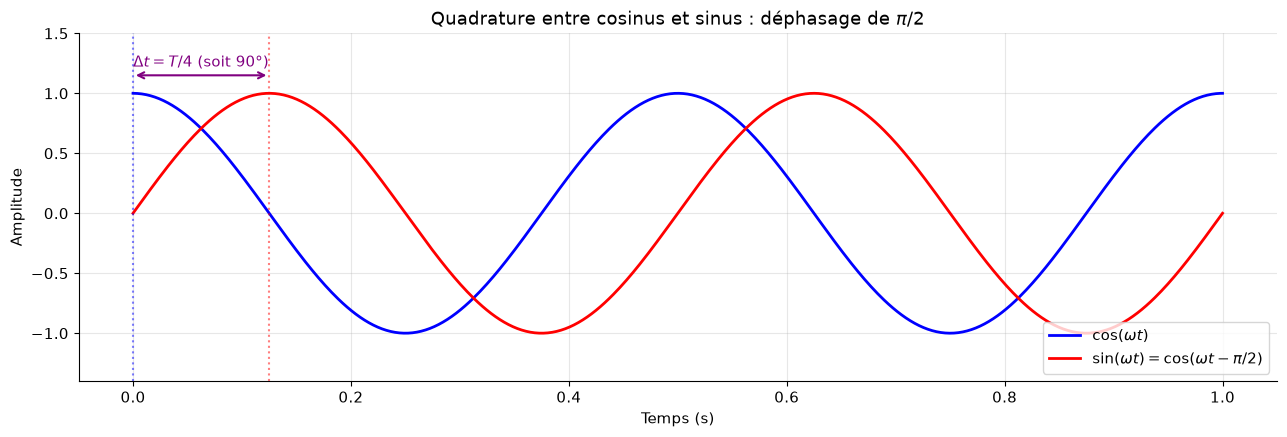

In [8]:
# =====================================================
# Vérification du déphasage 90° entre cos et sin
# =====================================================
t = np.linspace(0, 1, 500)
omega = 2*np.pi*2   # ω = 4π rad/s

cos_t = np.cos(omega * t)
sin_t = np.sin(omega * t)

# Décalage numérique : cos(ωt - π/2) = sin(ωt) ??
check = np.cos(omega * t - np.pi/2)
err = np.max(np.abs(check - sin_t))

print("=" * 55)
print("VÉRIFICATION DE LA QUADRATURE")
print("=" * 55)
print(f"Erreur max |cos(ωt - π/2) - sin(ωt)| = {err:.2e}")
print(f"(ordre de grandeur de l'epsilon machine  : {np.finfo(float).eps:.2e})")
print("→ cos et sin sont bien en quadrature (déphasage = 90°).")
print(r"\nIdentité utilisée : cos(ωt - π/2) = sin(ωt)")

# --- Tracé avec décalage mis en évidence ---
plt.figure(figsize=(13, 4.5))
plt.plot(t, cos_t, 'b-', lw=2, label=r'$\cos(\omega t)$')
plt.plot(t, sin_t, 'r-', lw=2, label=r'$\sin(\omega t) = \cos(\omega t - \pi/2)$')

# Marquer le décalage temporel = T/4
T = 1/(omega/(2*np.pi))
plt.axvline(0, color='b', ls=':', alpha=0.5)
plt.axvline(T/4, color='r', ls=':', alpha=0.5)
plt.annotate('', xy=(T/4, 1.15), xytext=(0, 1.15),
             arrowprops=dict(arrowstyle='<->', color='purple', lw=1.5))
plt.text(T/8, 1.22, r'$\Delta t = T/4$ (soit 90°)',
         color='purple', ha='center', fontsize=11)

plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.title(r'Quadrature entre cosinus et sinus : déphasage de $\pi/2$')
plt.ylim(-1.4, 1.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 4.2 Phaseur dans le plan complexe

Représentons $z(t) = A e^{j(\omega t + \phi)}$ comme un **vecteur tournant** dans le plan complexe. Chaque flèche correspond à un instant $t_k$.

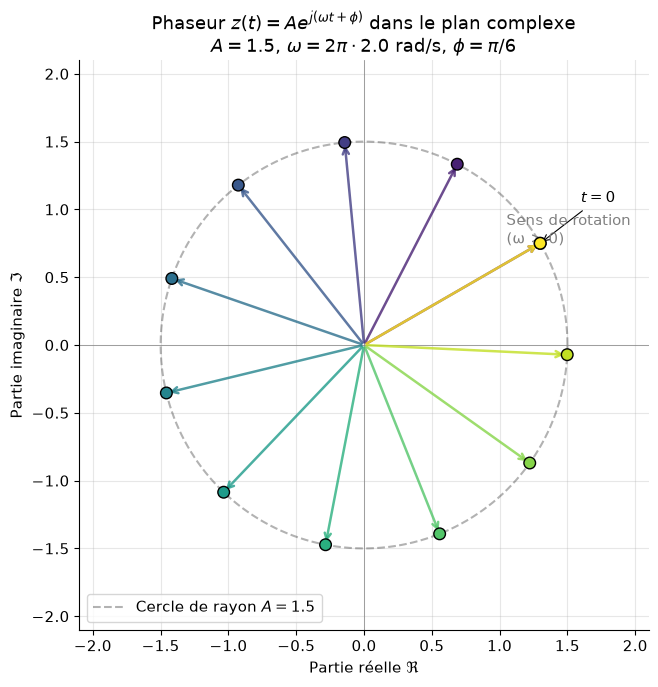

In [9]:
# =====================================================
# Phaseur : projection du vecteur tournant dans le plan complexe
# =====================================================
A, f, phi = 1.5, 2.0, np.pi/6

# On prend seulement quelques instants pour ne pas surcharger
t_phase = np.linspace(0, 1/f, 12)  # 1 période, 12 points
z_phase = A * np.exp(1j * (2*np.pi*f*t_phase + phi))

fig, ax = plt.subplots(figsize=(7, 7))

# Cercle de rayon A
theta_circle = np.linspace(0, 2*np.pi, 200)
ax.plot(A*np.cos(theta_circle), A*np.sin(theta_circle),
        'k--', alpha=0.3, label=rf'Cercle de rayon $A = {A}$')

# Axes
ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)

# Phaseurs sous forme de flèches, colorés par instant
colors = plt.cm.viridis(np.linspace(0, 1, len(t_phase)))
for i, (ti, zi, c) in enumerate(zip(t_phase, z_phase, colors)):
    ax.annotate('', xy=(zi.real, zi.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=c, lw=1.8, alpha=0.8))

# Points
ax.scatter(z_phase.real, z_phase.imag, c=t_phase, cmap='viridis',
           s=70, edgecolors='k', zorder=5)

# Annotation du point de départ
ax.annotate('$t = 0$',
            xy=(z_phase[0].real, z_phase[0].imag),
            xytext=(z_phase[0].real+0.3, z_phase[0].imag+0.3),
            fontsize=11, color='black',
            arrowprops=dict(arrowstyle='->', color='black', lw=0.8))

# Annotation : sens de rotation
ax.annotate('Sens de rotation\n(ω > 0)', xy=(A*0.7, A*0.5),
            fontsize=11, color='gray', ha='left')

ax.set_aspect('equal')
ax.set_xlim(-A*1.4, A*1.4)
ax.set_ylim(-A*1.4, A*1.4)
ax.set_xlabel(r'Partie réelle $\Re$')
ax.set_ylabel(r'Partie imaginaire $\Im$')
ax.set_title(rf'Phaseur $z(t) = A e^{{j(\omega t + \phi)}}$ dans le plan complexe' + '\n'
             rf'$A = {A}$, $\omega = 2\pi \cdot {f}$ rad/s, $\phi = \pi/6$')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## 4.3 Hélice 3D — la visualisation magistrale

En traçant $t$ sur un axe, $\Re\{z\}$ sur un second et $\Im\{z\}$ sur un troisième, on obtient une **hélice**. Les sinusoïdes réelle et imaginaire sont les **projections** de cette hélice sur les plans verticaux.

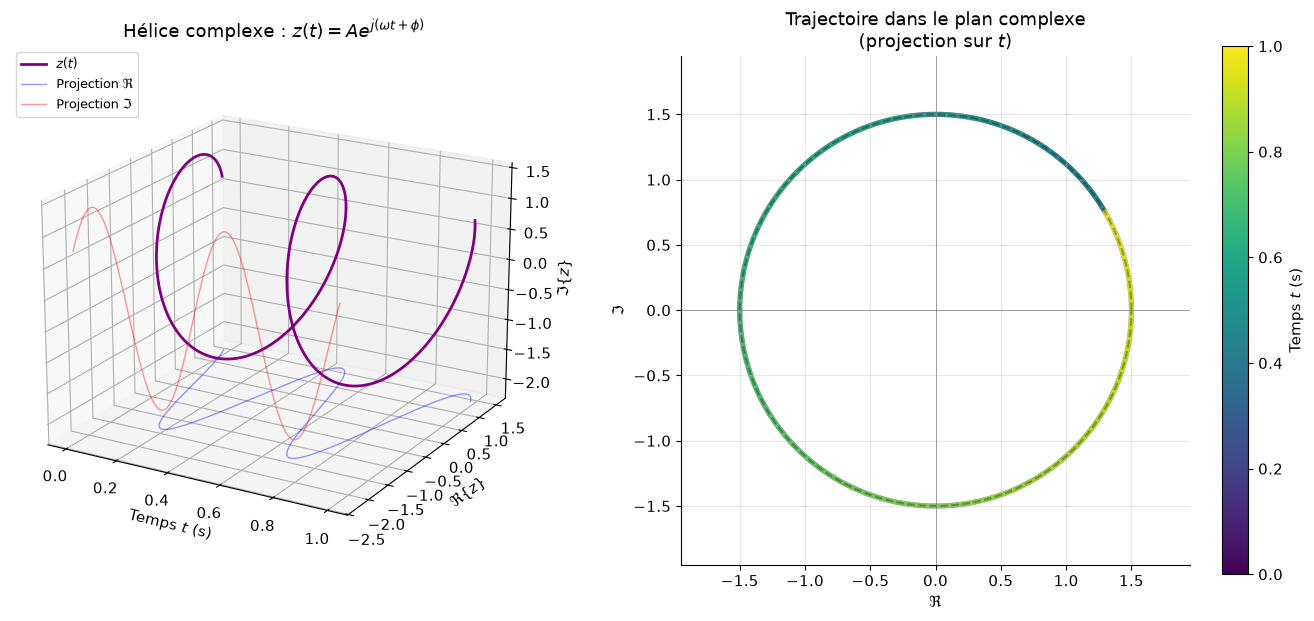

In [10]:
# =====================================================
# Hélice complexe 3D : visualisation magistrale
# =====================================================
A, f, phi = 1.5, 2.0, np.pi/6

t = np.linspace(0, 1, 800)
z = A * np.exp(1j * (2*np.pi*f*t + phi))
re_z, im_z = np.real(z), np.imag(z)

fig = plt.figure(figsize=(14, 6))

# --- Vue 3D ---
ax = fig.add_subplot(121, projection='3d')

# Hélice : t → (t, Re, Im)
ax.plot(t, re_z, im_z, color='purple', lw=2, label='$z(t)$')
# Ombre sur le plan Re-t (projection sur axe imaginaire nul)
ax.plot(t, re_z, np.full_like(t, -A*1.5), color='blue',
        alpha=0.4, lw=1, label=r'Projection $\Re$')
# Ombre sur le plan Im-t (projection sur axe réel nul)
ax.plot(t, np.full_like(t, -A*1.5), im_z, color='red',
        alpha=0.4, lw=1, label=r'Projection $\Im$')

ax.set_xlabel('Temps $t$ (s)')
ax.set_ylabel(r'$\Re\{z\}$')
ax.set_zlabel(r'$\Im\{z\}$')
ax.set_title(r'Hélice complexe : $z(t) = A e^{j(\omega t + \phi)}$')
ax.view_init(elev=20, azim=-60)
ax.legend(loc='upper left', fontsize=9)

# --- Vue polaire à droite (pour rappel) ---
ax2 = fig.add_subplot(122)
theta_c = np.linspace(0, 2*np.pi, 200)
ax2.plot(A*np.cos(theta_c), A*np.sin(theta_c), 'k--', alpha=0.3)
ax2.scatter(re_z, im_z, c=t, cmap='viridis', s=8, alpha=0.7)
ax2.set_aspect('equal')
ax2.set_xlim(-A*1.3, A*1.3)
ax2.set_ylim(-A*1.3, A*1.3)
ax2.axhline(0, color='gray', lw=0.5)
ax2.axvline(0, color='gray', lw=0.5)
ax2.set_xlabel(r'$\Re$')
ax2.set_ylabel(r'$\Im$')
ax2.set_title('Trajectoire dans le plan complexe\n(projection sur $t$)')
ax2.grid(True, alpha=0.3)

plt.colorbar(plt.cm.ScalarMappable(cmap='viridis',
             norm=plt.Normalize(t.min(), t.max())),
             ax=ax2, label='Temps $t$ (s)')

plt.tight_layout()
plt.show()

## 4.4 Animation du phaseur

Animer l'ensemble : à gauche le phaseur qui tourne dans le plan complexe, à droite la trace des parties réelle et imaginaire dans le temps.

> 💡 **Conseil** — Modifier les paramètres `A`, `f`, `phi` en tête de cellule et relancer pour observer les effets respectifs.

Animation prête. Mettre SAUVER_GIF=True pour générer 'phaseur.gif' (nécessite pillow).


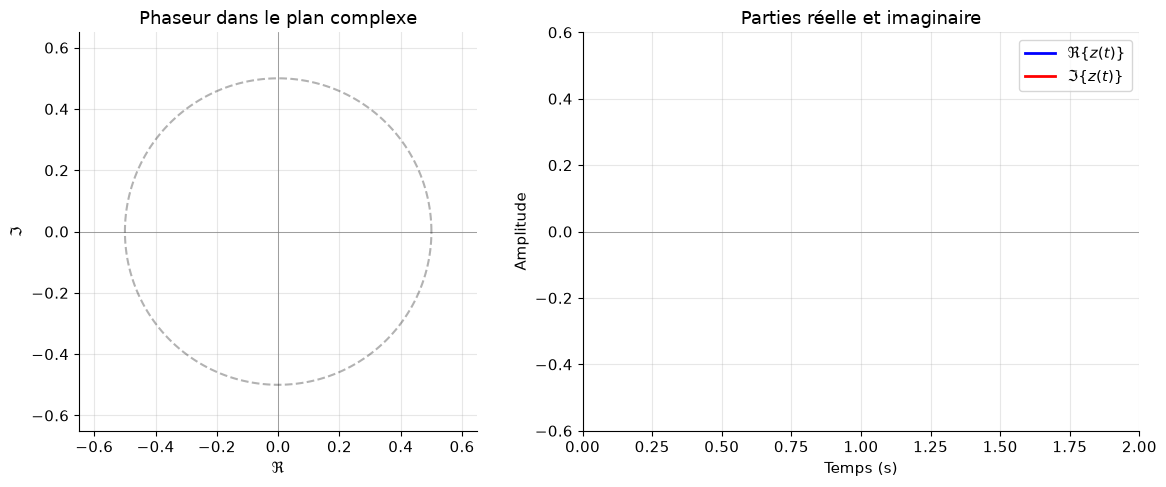

In [11]:
# =====================================================
# Animation du phaseur (génère optionnellement un GIF)
# =====================================================
from matplotlib.animation import FuncAnimation, PillowWriter

# Paramètres ajustables
A, f, phi = 0.5, 1.0, 0.8
omega = 2*np.pi*f
SAUVER_GIF = False   # passer à True pour générer le fichier 'phaseur.gif'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Axe 1 : plan complexe ---
ax1.set_xlim(-A*1.3, A*1.3)
ax1.set_ylim(-A*1.3, A*1.3)
ax1.set_aspect('equal')
ax1.axhline(0, color='gray', lw=0.5)
ax1.axvline(0, color='gray', lw=0.5)
theta_c = np.linspace(0, 2*np.pi, 200)
ax1.plot(A*np.cos(theta_c), A*np.sin(theta_c), 'k--', alpha=0.3)
phaseur_line, = ax1.plot([], [], 'b-', lw=2)
phaseur_dot, = ax1.plot([], [], 'bo', markersize=10)
proj_re, = ax1.plot([], [], 'b.', markersize=12)
ax1.set_title('Phaseur dans le plan complexe')
ax1.set_xlabel(r'$\Re$')
ax1.set_ylabel(r'$\Im$')

# --- Axe 2 : signal temporel ---
t_max = 2/f
ax2.set_xlim(0, t_max)
ax2.set_ylim(-A*1.2, A*1.2)
ax2.axhline(0, color='gray', lw=0.5)
cos_line, = ax2.plot([], [], 'b-', lw=2, label=r'$\Re\{z(t)\}$')
sin_line, = ax2.plot([], [], 'r-', lw=2, label=r'$\Im\{z(t)\}$')
ax2.set_title('Parties réelle et imaginaire')
ax2.set_xlabel('Temps (s)')
ax2.set_ylabel('Amplitude')
ax2.legend(loc='upper right')

# --- Données ---
t_all = np.linspace(0, t_max, 400)
z_all = A * np.exp(1j * (omega*t_all + phi))

def init():
    return phaseur_line, phaseur_dot, proj_re, cos_line, sin_line

def update(frame):
    t = t_all[frame]
    z = z_all[frame]
    phaseur_line.set_data([0, z.real], [0, z.imag])
    phaseur_dot.set_data([z.real], [z.imag])
    proj_re.set_data([z.real], [0])
    cos_line.set_data(t_all[:frame+1], np.real(z_all[:frame+1]))
    sin_line.set_data(t_all[:frame+1], np.imag(z_all[:frame+1]))
    return phaseur_line, phaseur_dot, proj_re, cos_line, sin_line

anim = FuncAnimation(fig, update, frames=len(t_all),
                     init_func=init, interval=20, blit=True)

plt.tight_layout()

# Sauvegarde optionnelle (décommenter ou mettre SAUVER_GIF=True)
if SAUVER_GIF:
    anim.save('phaseur.gif', writer=PillowWriter(fps=30))
    print("GIF sauvegardé : phaseur.gif")
else:
    print("Animation prête. Mettre SAUVER_GIF=True pour générer 'phaseur.gif' (nécessite pillow).")

plt.show()

## 4.5 Synthèse — Les 4 idées-force de la semaine

1. **Les nombres complexes sont l'outil naturel de la phase.** Multiplier deux complexes = multiplier les modules et additionner les angles. Cela transforme des convolutions en multiplications dans le domaine fréquentiel.

2. **La formule d'Euler relie exponentielle complexe et sinusoïde.** C'est le pont entre les mathématiques des systèmes LTI (qui aiment $e^{j\omega t}$) et la physique des signaux mesurables (qui sont réels).

3. **Trois notions de fréquence à ne pas confondre** : $f$ (Hz), $\omega = 2\pi f$ (rad/s), $\Omega = \omega T_e$ (rad/échantillon). La pulsation numérique $\Omega$ est un **angle**, pas une fréquence.

4. **L'exponentielle complexe est le phaseur.** C'est un vecteur tournant à vitesse angulaire $\omega$ dans le plan complexe. Sa projection sur l'axe réel est le cosinus, sur l'axe imaginaire est le sinus. Toute l'analyse spectrale en découle.

PARTIE 1 — NOMBRES COMPLEXES
z1 = (3+4j)  (forme cartésienne)
z2 = (1-2j)
z1 + z2 = (4+2j)
z1 - z2 = (2+6j)
z1 * z2 = (11-2j)
z1 / z2 = (-1+2j)

|z1| = 5.0000
arg(z1) = 0.9273 rad = 53.13°
|z2| = 2.2361
arg(z2) = -1.1071 rad = -63.43°

Forme polaire z1 : 5.0000 · e^(j · 0.9273)
Forme polaire z2 : 2.2361 · e^(j · -1.1071)


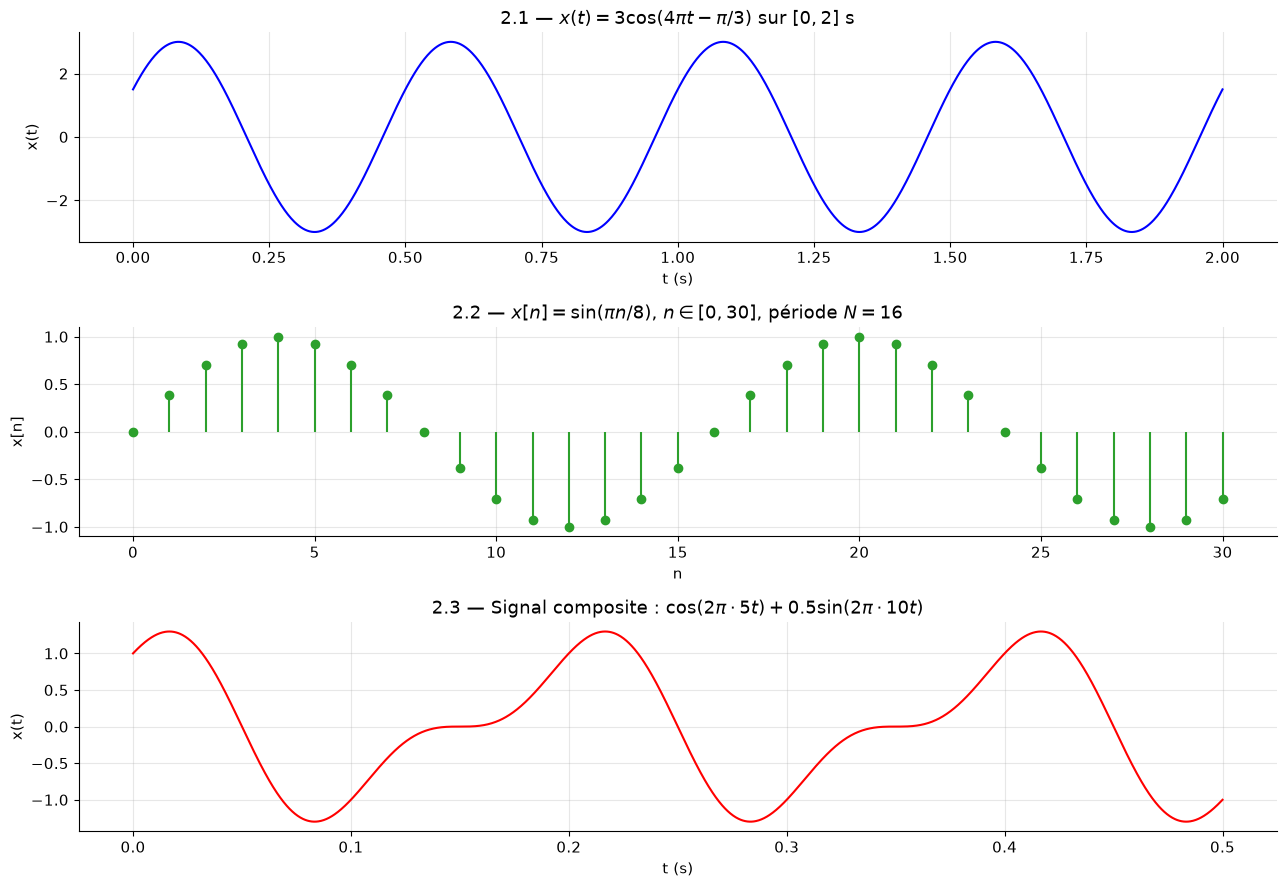


PARTIE 3 — REPRÉSENTATION COMPLEXE
x(t) = 2cos(3t + π/4)
→ z(t) = 2 e^(j(3t + π/4))
→ ℜ{z(t)} = 2cos(3t + π/4) = x(t)  ✓
→ ℑ{z(t)} = 2sin(3t + π/4)


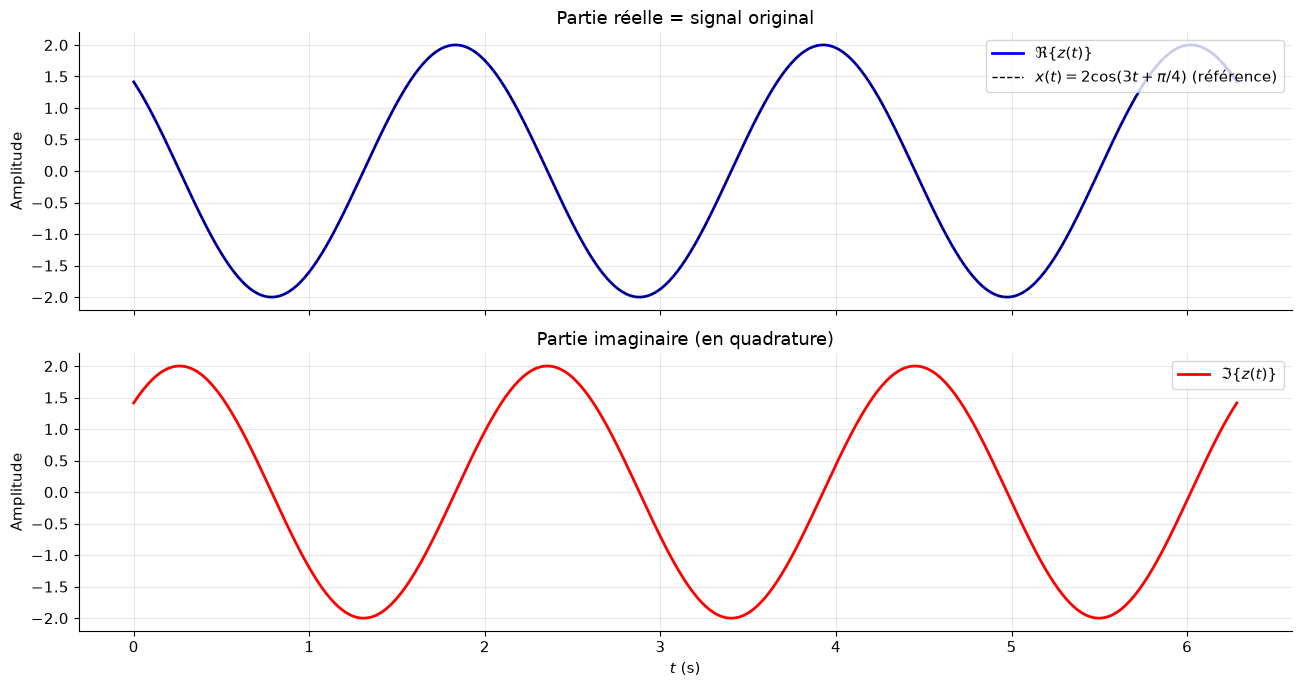


✓ Correction terminée.


In [12]:
# =====================================================
# CORRECTION COMPLÈTE — DEVOIR SEMAINE 2
# Passer AFFICHER_CORRIGE à True pour voir les résultats détaillés.
# =====================================================
AFFICHER_CORRIGE = True

if not AFFICHER_CORRIGE:
    print("Corrigé masqué. Mettre AFFICHER_CORRIGE=True pour l'afficher.")
else:

    # ---------- PARTIE 1 : Nombres complexes ----------
    z1 = 3 + 4j
    z2 = 1 - 2j

    print("=" * 55)
    print("PARTIE 1 — NOMBRES COMPLEXES")
    print("=" * 55)
    print(f"z1 = {z1}  (forme cartésienne)")
    print(f"z2 = {z2}")
    print(f"z1 + z2 = {z1 + z2}")
    print(f"z1 - z2 = {z1 - z2}")
    print(f"z1 * z2 = {z1 * z2}")
    print(f"z1 / z2 = {z1 / z2}")

    print(f"\n|z1| = {abs(z1):.4f}")
    print(f"arg(z1) = {np.angle(z1):.4f} rad = {np.degrees(np.angle(z1)):.2f}°")
    print(f"|z2| = {abs(z2):.4f}")
    print(f"arg(z2) = {np.angle(z2):.4f} rad = {np.degrees(np.angle(z2)):.2f}°")

    print(f"\nForme polaire z1 : {abs(z1):.4f} · e^(j · {np.angle(z1):.4f})")
    print(f"Forme polaire z2 : {abs(z2):.4f} · e^(j · {np.angle(z2):.4f})")

    # ---------- PARTIE 2 : Génération de signaux ----------

    # 2.1 — Signal continu
    t = np.linspace(0, 2, 1000)
    x_cont = 3 * np.cos(4*np.pi*t - np.pi/3)

    # 2.2 — Signal discret
    n_disc = np.arange(0, 31)
    x_disc = np.sin(np.pi * n_disc / 8)

    # 2.3 — Signal composite
    t_comp = np.linspace(0, 0.5, 2000)
    x_comp = np.cos(2*np.pi*5*t_comp) + 0.5*np.sin(2*np.pi*10*t_comp)

    fig, axes = plt.subplots(3, 1, figsize=(13, 9))

    axes[0].plot(t, x_cont, 'b-', lw=1.5)
    axes[0].set_xlabel('t (s)'); axes[0].set_ylabel('x(t)')
    axes[0].set_title(r'2.1 — $x(t) = 3\cos(4\pi t - \pi/3)$ sur $[0, 2]$ s')
    axes[0].grid(True, alpha=0.3)

    axes[1].stem(n_disc, x_disc, basefmt=' ', linefmt='C2-', markerfmt='C2o')
    axes[1].set_xlabel('n'); axes[1].set_ylabel('x[n]')
    axes[1].set_title(r'2.2 — $x[n] = \sin(\pi n/8)$, $n \in [0, 30]$, période $N = 16$')
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(t_comp, x_comp, 'r-', lw=1.5)
    axes[2].set_xlabel('t (s)'); axes[2].set_ylabel('x(t)')
    axes[2].set_title(r'2.3 — Signal composite : $\cos(2\pi \cdot 5t) + 0.5\sin(2\pi \cdot 10t)$')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ---------- PARTIE 3 : Représentation complexe ----------

    print("\n" + "=" * 55)
    print("PARTIE 3 — REPRÉSENTATION COMPLEXE")
    print("=" * 55)
    print("x(t) = 2cos(3t + π/4)")
    print("→ z(t) = 2 e^(j(3t + π/4))")
    print("→ ℜ{z(t)} = 2cos(3t + π/4) = x(t)  ✓")
    print("→ ℑ{z(t)} = 2sin(3t + π/4)")

    t3 = np.linspace(0, 2*np.pi, 500)
    z3 = 2 * np.exp(1j * (3*t3 + np.pi/4))

    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

    axes[0].plot(t3, np.real(z3), 'b-', lw=2, label=r'$\Re\{z(t)\}$')
    axes[0].plot(t3, 2*np.cos(3*t3 + np.pi/4), 'k--', lw=1,
                 label=r'$x(t) = 2\cos(3t + \pi/4)$ (référence)')
    axes[0].set_ylabel('Amplitude')
    axes[0].set_title('Partie réelle = signal original')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(t3, np.imag(z3), 'r-', lw=2, label=r'$\Im\{z(t)\}$')
    axes[1].set_xlabel('$t$ (s)')
    axes[1].set_ylabel('Amplitude')
    axes[1].set_title('Partie imaginaire (en quadrature)')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n✓ Correction terminée.")

---

## 📝 Corrigé — Partie 1 (détails mathématiques)

**1. Opérations élémentaires**

- **Somme** : $z_1 + z_2 = (3+1) + (4-2)j = 4 + 2j$.
- **Différence** : $z_1 - z_2 = (3-1) + (4+2)j = 2 + 6j$.
- **Produit** : $z_1 \cdot z_2 = (3)(1) - (4)(-2) + j[(3)(-2) + (4)(1)] = 3 + 8 + j(-6 + 4) = 11 - 2j$.
- **Quotient** : on multiplie numérateur et dénominateur par $z_2^* = 1 + 2j$ :

$$ \frac{z_1}{z_2} = \frac{(3+4j)(1+2j)}{(1-2j)(1+2j)} = \frac{3 + 6j + 4j + 8j^2}{1 + 4} = \frac{-5 + 10j}{5} = -1 + 2j $$

**2. Modules et arguments**

- $|z_1| = \sqrt{3^2 + 4^2} = 5$ ; $\arg(z_1) = \operatorname{atan2}(4, 3) \approx 0{,}927\ \text{rad} \approx 53{,}13^\circ$.
- $|z_2| = \sqrt{1^2 + (-2)^2} = \sqrt{5} \approx 2{,}236$ ; $\arg(z_2) = \operatorname{atan2}(-2, 1) \approx -1{,}107\ \text{rad} \approx -63{,}43^\circ$.

**3. Formes polaires**

$$ z_1 = 5\, e^{j \cdot 0{,}927} \qquad z_2 = \sqrt{5}\, e^{-j \cdot 1{,}107} $$

> 🔎 **Vérification intuitive du produit** — En forme polaire, $z_1 z_2$ devrait avoir pour module $5 \cdot \sqrt{5} = 5\sqrt{5} \approx 11{,}18$ et pour argument $0{,}927 - 1{,}107 = -0{,}180$ rad. Or $|11 - 2j| = \sqrt{121 + 4} = \sqrt{125} = 5\sqrt{5}$ ✓ et $\arg(11 - 2j) \approx -0{,}180$ rad ✓. **La cohérence confirme la règle « modules : produit, angles : somme ».**

---

## 📝 Corrigé — Partie 2 (détails)

**1. Signal continu** — $A = 3$, $f = 2$ Hz (car $\omega = 4\pi = 2\pi \cdot 2$), $\phi = -\pi/3$.

```python
t = np.linspace(0, 2, 1000)
x = 3 * np.cos(4*np.pi*t - np.pi/3)
plt.plot(t, x); plt.xlabel('t (s)'); plt.ylabel('x(t)'); plt.grid(); plt.show()
```

**2. Signal discret** — Période : $N = 2\pi / (\pi/8) = 16$ échantillons. Les échantillons $x[0]$ à $x[15]$ forment un cycle complet.

```python
n = np.arange(0, 31)
x = np.sin(np.pi * n / 8)
plt.stem(n, x); plt.xlabel('n'); plt.ylabel('x[n]'); plt.grid(); plt.show()
```

**3. Signal composite** — Superposition de deux sinusoïdes (5 Hz et 10 Hz), la seconde d'amplitude moitié. Le résultat présente une forme non sinusoïdale, mais **périodique** de fréquence fondamentale 5 Hz (car 10 Hz est un multiple entier de 5 Hz).

```python
t = np.linspace(0, 0.5, 2000)
x = np.cos(2*np.pi*5*t) + 0.5 * np.sin(2*np.pi*10*t)
plt.plot(t, x); plt.xlabel('t (s)'); plt.ylabel('x(t)'); plt.grid(); plt.show()
```

> 🔎 **Remarque** — Pour un affichage propre sur $[0, 0{,}5]$ s avec des composantes à 5 et 10 Hz, il faut au moins $f_e \geq 20 \cdot 10 = 200$ Hz pour éviter l'aliasing visuel. Ici on a utilisé 2000 points sur 0,5 s → $f_e = 4000$ Hz. Largement suffisant.

---

## 📝 Corrigé — Partie 3 (détails)

**1. Exponentielle complexe associée**

$$ z(t) = A \, e^{j(\omega t + \phi)} = 2 \, e^{j(3t + \pi/4)} $$

**2. Code Python**

```python
A = 2.0
omega = 3.0
phi = np.pi/4

t = np.linspace(0, 2*np.pi, 500)
z = A * np.exp(1j * (omega*t + phi))

plt.figure(figsize=(12, 4))
plt.plot(t, np.real(z), label='Partie réelle : 2cos(3t + π/4)')
plt.plot(t, np.imag(z), label='Partie imaginaire : 2sin(3t + π/4)')
plt.xlabel('t (s)'); plt.ylabel('Amplitude')
plt.title(r'Exponentielle complexe $z(t) = 2 e^{j(3t + \pi/4)}$')
plt.grid(); plt.legend(); plt.show()
```

**3. Vérification**

La partie réelle $\Re\{z(t)\} = 2\cos(3t + \pi/4)$ correspond exactement au signal original $x(t)$. On vérifie visuellement que :
- Les deux courbes (parties réelle et imaginaire) sont **en quadrature** (décalées d'un quart de période, soit $\pi/2$).
- Elles ont la **même amplitude** $A = 2$.
- Elles ont la **même pulsation** $\omega = 3$ rad/s.

> 🔑 **À retenir pour la suite** — Le signal réel $x(t)$ et sa « version imaginaire » ne sont pas indépendants : **ensemble**, ils forment le phaseur $z(t)$, qui est **l'objet mathématique complet** manipulé dans toute la suite du cours (filtrage, transformée de Fourier, transformée en Z, etc.).